In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from skimage.metrics import structural_similarity, mean_squared_error

In [2]:
# ДЗ 2
# Зашумить изображение при помощи шума гаусса, постоянного шума.
# Протестировать медианный фильтр, фильтр гаусса, билатериальный фильтр, фильтр нелокальных средних с различными параметрами.
# Выяснить, какой фильтр показал лучший результат фильтрации шума.

In [3]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
print(image_gray.shape)

(675, 1200)


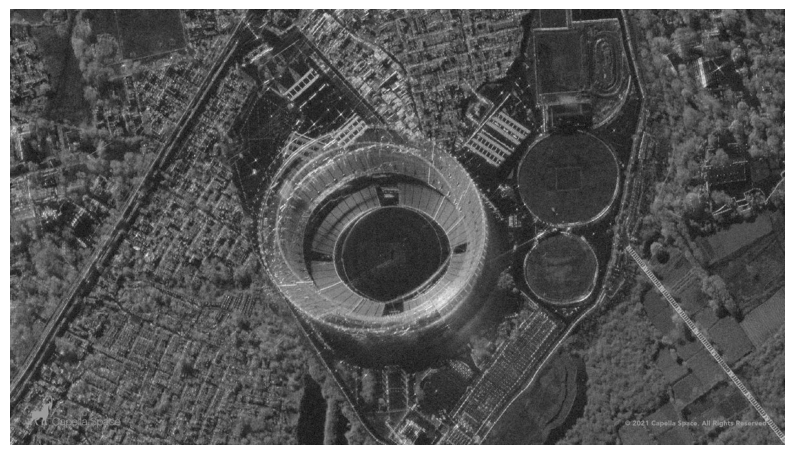

In [4]:
plt.figure(figsize=(10, 6))
plt.imshow(image_gray, cmap="gray")
plt.axis('off')
plt.show()

## Зашумление

In [5]:
np.random.seed(1)

# шум гаусса, считаем в int16 чтобы не было переполнения
noise_gauss = np.zeros(image_gray.shape, np.int16)
cv2.randn(noise_gauss, 0, 20)
image_noise_gauss = np.clip(image_gray.astype(np.int16) + noise_gauss, 0, 255).astype(np.uint8)

# постоянный (равномерный) шум в диапазоне [-40, 40]
noise_const = np.random.uniform(-40, 40, image_gray.shape)
image_noise_const = np.clip(image_gray + noise_const, 0, 255).astype(np.uint8)

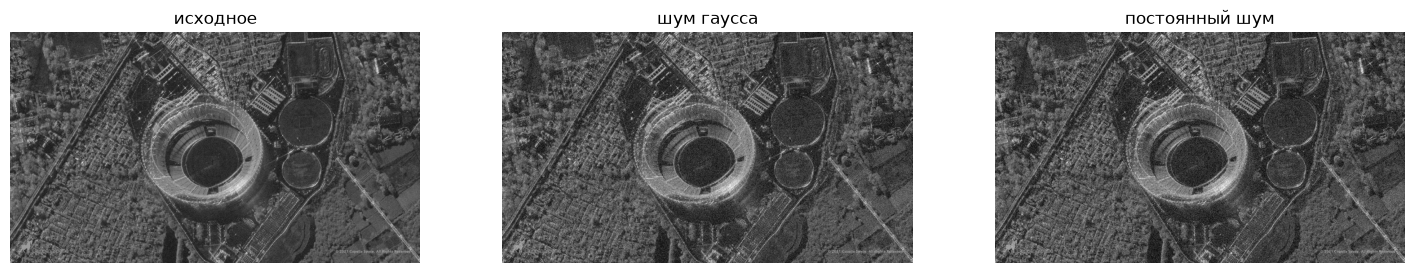

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].imshow(image_gray, cmap="gray")
ax[0].set_title('исходное')
ax[1].imshow(image_noise_gauss, cmap="gray")
ax[1].set_title('шум гаусса')
ax[2].imshow(image_noise_const, cmap="gray")
ax[2].set_title('постоянный шум')
for a in ax:
    a.axis('off')
plt.show()

In [7]:
def metrics(img):
    mse = mean_squared_error(image_gray, img)
    ssim = structural_similarity(image_gray, img)
    return mse, ssim

print('гаусс:     MSE = %.2f, SSIM = %.4f' % metrics(image_noise_gauss))
print('постоянный: MSE = %.2f, SSIM = %.4f' % metrics(image_noise_const))

гаусс:     MSE = 396.29, SSIM = 0.5734
постоянный: MSE = 531.56, SSIM = 0.5094


## Фильтрация с разными параметрами

In [8]:
def test_filters(noisy):
    res = []
    for k in [3, 5, 7, 9]:
        out = cv2.medianBlur(noisy, k)
        res.append(['median', 'k=%d' % k, *metrics(out)])
    for k in [3, 5, 7]:
        for s in [0, 1, 2]:
            out = cv2.GaussianBlur(noisy, (k, k), s)
            res.append(['gauss', 'k=%d s=%d' % (k, s), *metrics(out)])
    for d in [5, 9]:
        for sc in [25, 50, 75, 100]:
            out = cv2.bilateralFilter(noisy, d, sc, 75)
            res.append(['bilateral', 'd=%d sc=%d' % (d, sc), *metrics(out)])
    for h in [5, 10, 15, 20, 25]:
        for t in [5, 7]:
            out = cv2.fastNlMeansDenoising(noisy, None, h, t, 21)
            res.append(['nlm', 'h=%d t=%d' % (h, t), *metrics(out)])
    return pd.DataFrame(res, columns=['filter', 'params', 'MSE', 'SSIM'])

In [9]:
df_gauss = test_filters(image_noise_gauss)
df_gauss.sort_values('MSE').head(10)

,filter,params,MSE,SSIM
4,gauss,k=3 s=0,119.810764,0.769245
5,gauss,k=3 s=1,123.760969,0.761885
14,bilateral,d=5 sc=50,124.888973,0.750636
8,gauss,k=5 s=1,133.938720,0.744612
11,gauss,k=7 s=1,135.753704,0.741417
27,nlm,h=20 t=5,137.571426,0.696401
15,bilateral,d=5 sc=75,137.672606,0.726588
6,gauss,k=3 s=2,138.564241,0.734445
7,gauss,k=5 s=0,140.271475,0.733073
16,bilateral,d=5 sc=100,149.178431,0.708639


In [10]:
df_const = test_filters(image_noise_const)
df_const.sort_values('MSE').head(10)

,filter,params,MSE,SSIM
4,gauss,k=3 s=0,138.495340,0.740711
5,gauss,k=3 s=1,140.476122,0.736040
8,gauss,k=5 s=1,144.899552,0.726632
11,gauss,k=7 s=1,146.242986,0.724154
27,nlm,h=20 t=5,147.916821,0.701019
14,bilateral,d=5 sc=50,148.358537,0.721266
7,gauss,k=5 s=0,150.096051,0.717064
15,bilateral,d=5 sc=75,150.184435,0.710471
6,gauss,k=3 s=2,153.286963,0.711843
16,bilateral,d=5 sc=100,159.658805,0.694530


In [11]:
# лучший вариант каждого фильтра
best_gauss = df_gauss.loc[df_gauss.groupby('filter')['MSE'].idxmin()]
best_const = df_const.loc[df_const.groupby('filter')['MSE'].idxmin()]
print('Шум гаусса')
print(best_gauss.to_string(index=False))
print()
print('Постоянный шум')
print(best_const.to_string(index=False))

Шум гаусса
   filter    params        MSE     SSIM
bilateral d=5 sc=50 124.888973 0.750636
    gauss   k=3 s=0 119.810764 0.769245
   median       k=3 170.854844 0.684623
      nlm  h=20 t=5 137.571426 0.696401

Постоянный шум
   filter    params        MSE     SSIM
bilateral d=5 sc=50 148.358537 0.721266
    gauss   k=3 s=0 138.495340 0.740711
   median       k=3 232.281273 0.609916
      nlm  h=20 t=5 147.916821 0.701019


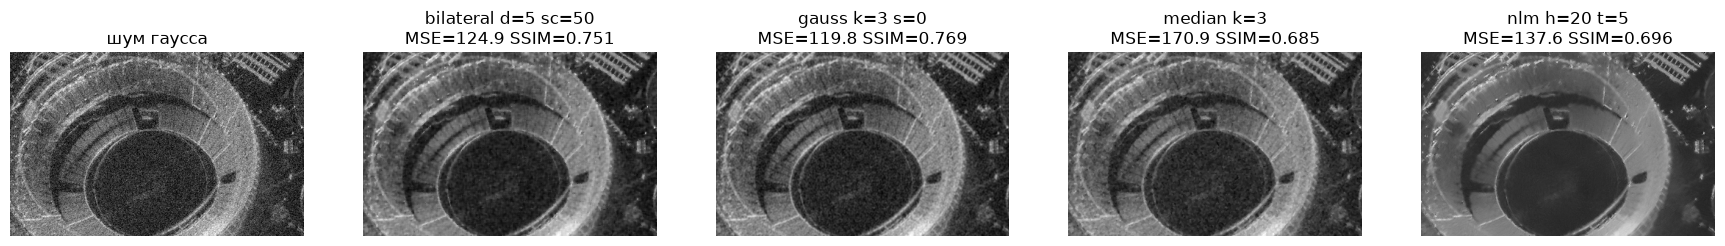

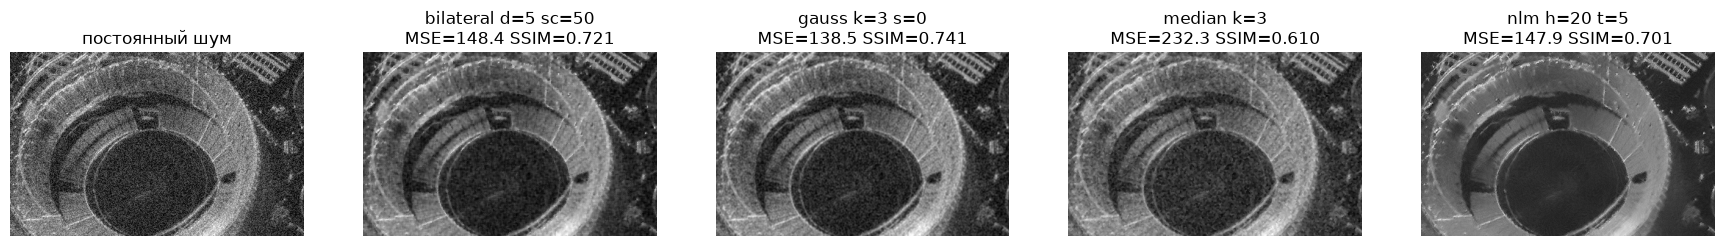

In [12]:
def apply(name, p, img):
    v = dict(x.split('=') for x in p.split())
    v = {key: int(val) for key, val in v.items()}
    if name == 'median':
        return cv2.medianBlur(img, v['k'])
    if name == 'gauss':
        return cv2.GaussianBlur(img, (v['k'], v['k']), v['s'])
    if name == 'bilateral':
        return cv2.bilateralFilter(img, v['d'], v['sc'], 75)
    return cv2.fastNlMeansDenoising(img, None, v['h'], v['t'], 21)

for title, noisy, best in [('шум гаусса', image_noise_gauss, best_gauss), ('постоянный шум', image_noise_const, best_const)]:
    fig, ax = plt.subplots(1, 5, figsize=(22, 4))
    # показываем кусок, чтобы было видно разницу
    ax[0].imshow(noisy[200:450, 400:800], cmap="gray")
    ax[0].set_title(title)
    for i, row in enumerate(best.itertuples(), 1):
        out = apply(row.filter, row.params, noisy)
        ax[i].imshow(out[200:450, 400:800], cmap="gray")
        ax[i].set_title('%s %s\nMSE=%.1f SSIM=%.3f' % (row.filter, row.params, row.MSE, row.SSIM))
    for a in ax:
        a.axis('off')
    plt.show()

## Вывод

Без фильтрации MSE для шума гаусса было около 396, для постоянного около 532.

Для обоих видов шума лучше всего сработал фильтр гаусса с маленьким ядром 3x3 (MSE примерно 120 и 138, SSIM 0.77 и 0.74). Близко к нему билатеральный фильтр с d=5 и sigmaColor=50 и NLM с h=20. Медианный фильтр оказался хуже всех, он больше подходит для импульсного шума (соль и перец), а здесь шум аддитивный и распределен по всем пикселям.

При увеличении размера ядра у всех фильтров изображение начинает сильно размываться и ошибка растет, поэтому маленькие окна дали лучший результат. У NLM картинка визуально самая гладкая, но мелкие детали снимка тоже пропадают, из-за этого SSIM у него ниже.